# Where vibrational frequencies come from

By the end of this you will have computed the vibrational energy levels of a chemical bond from scratch,
seen why the textbook spring model fails, and run into a bottleneck the project is about.

Should take about 25 minutes. Run every cell in order.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh

# everything below is in atomic units, which just means hbar = 1 and the numbers are small.
# there is a conversion to real spectroscopy units at the end.
HARTREE_TO_CM = 219474.63

## A chemical bond is a particle in a well

Here is the only chemistry you need for the first half.

Two atoms joined by a bond have some distance they prefer. Squash them together and they push back.
Pull them apart and they pull back. If you plot the molecule's energy against the bond length you get
a valley, with the preferred distance at the bottom.

The atoms are not sitting still at the bottom. They vibrate. And because this is quantum mechanics,
the vibration cannot have just any energy, only certain allowed values. Those allowed values are
what an infrared spectrometer measures: the molecule absorbs a photon when the photon energy exactly
matches the gap between two of them.

So our job is to find the allowed energies of a particle sitting in a valley. That is the
time independent Schrodinger equation in one dimension:

$$-\frac{1}{2m}\frac{d^2\psi}{dx^2} + V(x)\,\psi = E\,\psi$$

The left side is a linear operator acting on $\psi$. Put $x$ on a grid, replace the second derivative
with a finite difference, and the operator becomes a matrix. Then it is an ordinary eigenvalue problem
and `scipy` does the rest.

One bookkeeping note. The $m$ in that equation is the reduced mass of the two atoms, which is what you
get when you rewrite a two body problem as one particle moving in a fixed potential. This is the same trick as the two body problem in classical mechanics.

*Note:* Some may object to referring to a bond as a particle in a well without more caveats. More on this on a later day.

In [2]:
def vibrational_hamiltonian(x, V, mass):
    """Build H on a grid using the usual three point second derivative."""
    n = len(x)
    dx = x[1] - x[0]

    # the second derivative stencil is (-2 on the diagonal, 1 on either side) over dx squared,
    # and the kinetic operator carries a minus sign, so the signs below end up flipped.
    main = np.full(n, 2.0)
    off = np.full(n - 1, -1.0)
    T = (np.diag(main) + np.diag(off, 1) + np.diag(off, -1)) / (2 * mass * dx**2)

    return T + np.diag(V)

## The spring model

Start with the version from intro physics: the valley is a parabola, so the bond is a spring obeying
Hooke's law. We will use numbers roughly matching an H-H bond.

In [3]:
mass = 918.0        # reduced mass of two hydrogen atoms in atomic units
D = 0.17            # how deep the valley is
a = 1.03            # how steep its walls are

omega = a * np.sqrt(2 * D / mass)   # the spring frequency that matches that valley near the bottom

x = np.linspace(-1.2, 4.5, 900)     # displacement from the preferred bond length
V_harmonic = 0.5 * mass * omega**2 * x**2

E_harm, psi_harm = eigh(vibrational_hamiltonian(x, V_harmonic, mass))

print("first six levels:")
for n in range(6):
    print(f"  n={n}   E = {E_harm[n]:.6f}")

print("\ngaps between neighbouring levels:")
for n in range(4):
    print(f"  {n}->{n+1}   {E_harm[n+1] - E_harm[n]:.6f}")

first six levels:
  n=0   E = 0.009911
  n=1   E = 0.029731
  n=2   E = 0.049550
  n=3   E = 0.069367
  n=4   E = 0.089182
  n=5   E = 0.108996

gaps between neighbouring levels:
  0->1   0.019821
  1->2   0.019819
  2->3   0.019817
  3->4   0.019815


Every gap is the same number. That is the defining feature of a harmonic oscillator and it is also why the spring model is so appealing: one frequency describes the entire ladder.

It is also wrong, and here is exactly why.

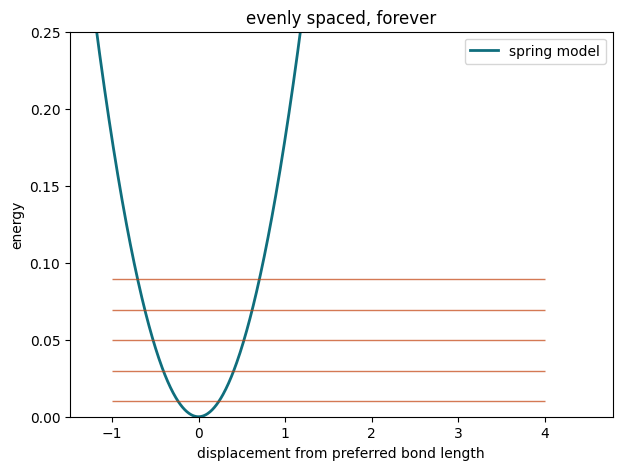

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x, V_harmonic, color="#0f6e7d", lw=2, label="spring model")

for n in range(5):
    ax.hlines(E_harm[n], -1.0, 4.0, color="#c2410c", lw=1, alpha=0.7)

ax.set_ylim(0, 0.25)
ax.set_xlabel("displacement from preferred bond length")
ax.set_ylabel("energy")
ax.set_title("evenly spaced, forever")
ax.legend()
plt.show()

## Real bonds will break

Look at where that parabola is heading. It is climbing without a limit, which says that no matter how hard you pull, the atoms never separate. That is not true in reality. Stretching a bond far enough will get you two free
atoms, and the energy stops rising.

The standard shape with that behaviour is the Morse potential:

$$V(x) = D\left(1 - e^{-ax}\right)^2$$

Near the bottom it looks almost identical to the parabola. Far out it flattens off at $D$, the energy
it takes to actually break the bond.

It is the same solver, just a different `V`.

In [5]:
V_morse = D * (1 - np.exp(-a * x))**2

E_morse, psi_morse = eigh(vibrational_hamiltonian(x, V_morse, mass))

print("gaps between neighbouring levels:")
for n in range(5):
    print(f"  {n}->{n+1}   {E_morse[n+1] - E_morse[n]:.6f}")

gaps between neighbouring levels:
  0->1   0.018665
  1->2   0.017508
  2->3   0.016352
  3->4   0.015196
  4->5   0.014041


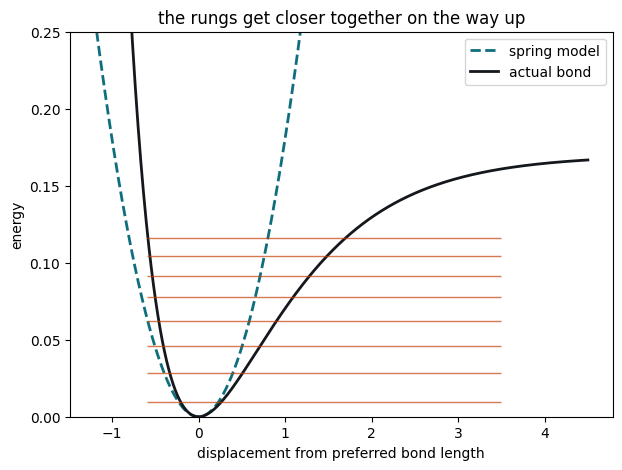

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x, V_harmonic, color="#0f6e7d", lw=2, ls="--", label="spring model")
ax.plot(x, V_morse, color="#14181d", lw=2, label="actual bond")

for n in range(8):
    if E_morse[n] < D:
        ax.hlines(E_morse[n], -0.6, 3.5, color="#c2410c", lw=1, alpha=0.7)

ax.set_ylim(0, 0.25)
ax.set_xlabel("displacement from preferred bond length")
ax.set_ylabel("energy")
ax.set_title("the rungs get closer together on the way up")
ax.legend()
plt.show()

## That squeeze described above has a name

The gaps shrink as you climb. Chemists call this anharmonicity, which is a slightly grand word for "the valley is not a parabola."

The gap that matters most is the very first one, from the ground level to the one above it. Almost every molecule sits in its ground level at room temperature, so that first step is the strong peak you see in an infrared spectrum. It has a name too: the fundamental.

Let us see how badly the spring model gets it.

In [7]:
fundamental_harm = (E_harm[1] - E_harm[0]) * HARTREE_TO_CM
fundamental_morse = (E_morse[1] - E_morse[0]) * HARTREE_TO_CM

print(f"spring model says   {fundamental_harm:8.1f} cm-1")
print(f"real bond says      {fundamental_morse:8.1f} cm-1")
print(f"off by              {fundamental_harm - fundamental_morse:8.1f} cm-1")

spring model says     4350.1 cm-1
real bond says        4096.5 cm-1
off by                 253.6 cm-1


Those units are wavenumbers, written cm-1. Spectroscopists use them instead of energy because they are
proportional to it and the numbers land in a convenient range. Every frequency you will see in this
project is quoted that way.

A couple of hundred wavenumbers off. For reference, when people say a calculation is accurate enough to
be useful they usually mean within a few wavenumbers. So the spring model misses by roughly a factor of
a hundred more than we can tolerate.

Everything from here is about closing that gap.

## Molecules have more than one bond

A real molecule does not vibrate in one way. Water has three independent motions, formic acid has nine.
Each one is called a mode, and the general count is 3N minus 6 for a molecule with N atoms, or 3N minus 5
if the atoms sit in a straight line. You can get that from counting degrees of freedom: 3N coordinates
total, minus 3 for sliding the whole molecule around and 3 for rotating it.

If the modes ignored each other, this would be easy. Solve each one separately, add the energies, done.

They do not ignore each other. Stretching one bond changes how stiff its neighbour feels. We can write
that down directly: add a term proportional to $x_1^2 x_2^2$, which makes the curvature each mode sees
depend on where the other one is.

To write the Hamiltonian for two coupled modes we need a basis. The natural choice is products of the
single mode solutions we already have: level $n$ in the first mode together with level $m$ in the second.

Those products are what the project calls configurations, and the whole rest of this notebook is about how many of them you can deal with.

In [8]:
def operator_matrix(x, psi, n_levels, f):
    """Matrix elements of some function of x, in the single mode states we already have."""
    p = psi[:, :n_levels]
    return p.T @ np.diag(f(x)) @ p


n_levels = 14
coupling = 20.0

# second mode is a bit stiffer so the two have different frequencies, which is the normal situation
V_morse_2 = D * (1 - np.exp(-1.35 * a * x))**2
E2, psi2 = eigh(vibrational_hamiltonian(x, V_morse_2, mass))

S1 = operator_matrix(x, psi_morse, n_levels, lambda v: v**2)
S2 = operator_matrix(x, psi2, n_levels, lambda v: v**2)

I = np.eye(n_levels)
H_uncoupled = np.kron(np.diag(E_morse[:n_levels]), I) + np.kron(I, np.diag(E2[:n_levels]))
H_two_mode = H_uncoupled + coupling * np.kron(S1, S2)

E_two, C_two = eigh(H_two_mode)

print(f"basis size: {n_levels} levels x {n_levels} levels = {n_levels**2} configurations")
print(f"ground state energy: {E_two[0]:.6f}")
print(f"if we ignored the coupling: {np.min(np.diag(H_uncoupled)):.6f}")

basis size: 14 levels x 14 levels = 196 configurations
ground state energy: 0.029714
if we ignored the coupling: 0.022882


That Kronecker product is doing real work, so it is worth a sentence. A configuration is a pair
(level in mode one, level in mode two). Writing the basis in that order means an operator acting only on
mode one becomes `kron(something, I)`, and the coupling term, which acts on both, becomes
`kron(S1, S2)`. Same structure you would use for two qubits.

## Now the problem

Fourteen levels per mode and two modes gave us 196 configurations. Perfectly fine.

Watch what happens when the molecule gets bigger.

In [9]:
levels_per_mode = 8

print("modes    configurations")
for n_modes in [2, 3, 4, 6, 9, 12]:
    print(f"{n_modes:5d}    {levels_per_mode**n_modes:,}")

modes    configurations
    2    64
    3    512
    4    4,096
    6    262,144
    9    134,217,728
   12    68,719,476,736


Nine modes is formic acid, a molecule with five atoms. Already 134 million configurations. Twelve modes
is methanol, which is six atoms, and you are into the tens of billions.

The matrix has that many rows. You cannot build it, let alone diagonalize it.

## So you throw most of them away

Here is the thing that makes this tractable. Go back to the two mode problem and look at how much each
configuration actually contributes to the ground state.

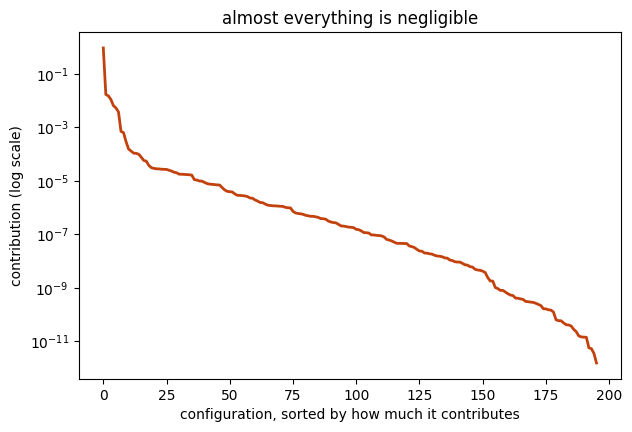

top   1 configurations hold  93.82% of the state
top   2 configurations hold  95.52% of the state
top   8 configurations hold  99.77% of the state
top  32 configurations hold  99.98% of the state
top 100 configurations hold 100.00% of the state


In [10]:
weights = np.sort(C_two[:, 0]**2)[::-1]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogy(weights, color="#c2410c", lw=2)
ax.set_xlabel("configuration, sorted by how much it contributes")
ax.set_ylabel("contribution (log scale)")
ax.set_title("almost everything is negligible")
plt.show()

for k in [1, 2, 8, 32, 100]:
    print(f"top {k:3d} configurations hold {weights[:k].sum()*100:6.2f}% of the state")

A handful of configurations carry nearly all of it and the rest round to nothing. That is not special to
this example, it is true for essentially every molecule, and it is the only reason any of this works.

So the plan is: keep the configurations that matter, drop the rest, and diagonalize the small matrix you
are left with. Let us check that actually works.

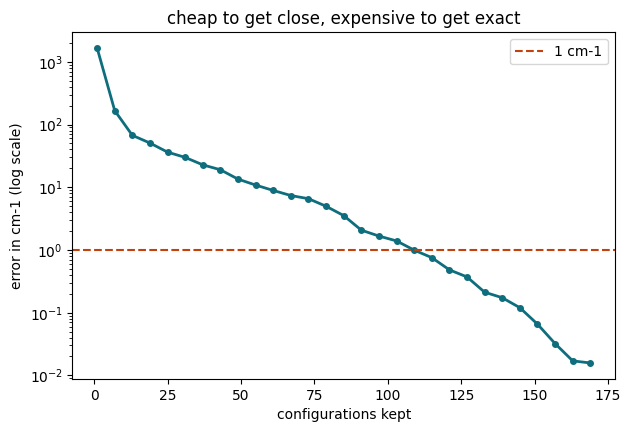

In [11]:
order = np.argsort(C_two[:, 0]**2)[::-1]   # cheating for now by using the answer we already have
exact = E_two[0]

sizes, errors = [], []
for k in range(1, 170, 6):
    keep = order[:k]
    sub = H_two_mode[np.ix_(keep, keep)]
    sizes.append(k)
    errors.append(abs(eigh(sub, eigvals_only=True)[0] - exact) * HARTREE_TO_CM)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogy(sizes, errors, "o-", color="#0f6e7d", lw=2, ms=4)
ax.axhline(1.0, color="#c2410c", ls="--", lw=1.5, label="1 cm-1")
ax.set_xlabel("configurations kept")
ax.set_ylabel("error in cm-1 (log scale)")
ax.set_title("cheap to get close, expensive to get exact")
ax.legend()
plt.show()

Worth reading that curve carefully rather than just nodding at it.

Ten configurations out of 196 takes the error from about 1600 wavenumbers down to 80. That is a huge return for five percent of the work. But getting under one wavenumber, which is roughly where you need to be, takes over half the basis. Cheap to get close, expensive to get right, and the expensive part is where the whole research problem lives.

## The catch, which is our project

Read the first line of that last cell again. To sort the configurations by importance, we used
`C_two[:, 0]`, the answer. We picked the important ones by already knowing which ones were important.

That is not available on a real problem. If you could compute the full ground state you would not need
to truncate in the first place.

So you need a rule that guesses which configurations will matter before you have solved anything.
Everyone has a rule. The standard one uses perturbation theory to score candidates and keeps the
high scorers.

The question our project asks is whether a quantum computer can guess better. You prepare an approximate
state on the machine, measure it a few hundred thousand times, and keep whichever configurations come
back. Nobody has checked whether that beats the classical rule for vibrations.

If that is the part you find interesting, the other notebook is entirely about it.

## Things to poke at

- Turn `coupling` up and down. Where does the number of configurations you need start to blow up?
- Change `a` in the Morse potential, which controls how far from a parabola the valley is. What happens
  to the gap between the spring answer and the real one?
- Add a third mode. The Kronecker products chain, so `np.kron(np.kron(A, B), C)` works. Watch your
  memory.